# MRP Shortage Prioritization & Shortage Risk Index (SRI)
## Decision-Grade Supply Chain Analytics for Multi-Sector Manufacturing

**Author:** Mohammad A. Zachariah
**Role:** Data Analyst (SQL, Python, Supply Chain Analytics)
**Profile:** [LinkedIn](https://www.linkedin.com/in/mo-zachariah) | **Email:** mohammad.a.zachariah@gmail.com
**Dataset:** 100% Synthetic Multi-Sector Pharma/Healthcare Manufacturing Data (No proprietary employer data)

---

### Executive Summary & Business Question
In high-mix, regulated manufacturing across Cosmetics, Human Pharmaceuticals, Veterinary Medicine, and Food Supplements, supply chain planners face daily procurement bottlenecks. When working capital is constrained and suppliers impose variable lead times (7 to 90 days), procurement teams cannot expedite all shortages simultaneously.

**The Core Business Question:**
> *When 24 raw material and packaging components face stockouts across 60 open production orders, which purchase orders and supplier expedites must be prioritized to protect high-criticality production schedules while avoiding working capital waste?*

### The Analytic Approach
1. **Automated Data Quality Audit:** Pre-computation identification of ERP/WMS anomalies (duplicate lots, phantom purchase orders, null quantities, negative inventory balances, expired lots marked released, and orphan BOMs).
2. **Time-Phased Gross-to-Net MRP Explosion:** In-database recursive requirement explosion via SQLite window functions and Common Table Expressions (CTEs), enforcing component lead-time feasibility.
3. **Shortage Risk Index (SRI):** A multi-factor objective prioritization metric that combines financial shortage value, product portfolio criticality (ABC classification), and order lead-time urgency.
4. **Rank Stability Sensitivity Analysis:** Stress-testing SRI rankings across weight perturbations ($\pm 20\%$) and urgency horizon shifts (15 to 45 days).

In [1]:
import os
import json
import sqlite3
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# Chart and display settings
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Helvetica", "Arial"]
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 1000)

DB_PATH = "data/mrp.db"
conn = sqlite3.connect(DB_PATH)
print(f"Connected to SQLite Database: {DB_PATH}")

# Verify table counts
tables = ["products", "components", "boms", "inventory_lots", "purchase_orders", "production_orders"]
table_counts = {t: pd.read_sql_query(f"SELECT COUNT(*) as cnt FROM {t}", conn)["cnt"].iloc[0] for t in tables}
for t, c in table_counts.items():
    print(f"  - {t:<20}: {c} rows")

Connected to SQLite Database: data/mrp.db
  - products            : 40 rows
  - components          : 120 rows
  - boms                : 138 rows
  - inventory_lots      : 305 rows
  - purchase_orders     : 52 rows
  - production_orders   : 60 rows


## 1. Data Quality Audit & Sanitization

Real-world ERP systems are rarely pristine. Inventory records frequently suffer from negative balances due to delayed backflushing, duplicate PO numbers from EDI re-transmissions, uninspected expired material improperly marked `RELEASED`, and obsolete BOM references.

Before running MRP explosion logic, our pipeline executes an automated data quality audit (`out/data_quality.csv`), logging and resolving anomalies deterministically.

In [2]:
from src.pipeline import audit_data_quality

df_audit, clean_data = audit_data_quality(conn)
print(f"Detected and remediated {df_audit['detected_count'].sum()} dirty data records across {len(df_audit)} distinct vulnerability classes:\n")
df_audit

Detected and remediated 25 dirty data records across 6 distinct vulnerability classes:



,issue_type,table_name,detected_count,action_taken
0,duplicate_inventory_lots,inventory_lots,3,Deduplicated by lot_id keeping primary entry
1,duplicate_purchase_orders,purchase_orders,2,Deduplicated by po_id keeping primary entry
2,null_quantity_lots,inventory_lots,4,Excluded from available stock (zero-imputed)
3,negative_quantity_lots,inventory_lots,5,Quarantined and excluded pending cycle count r...
4,expired_released_lots,inventory_lots,8,Reclassified status to EXPIRED and excluded fr...
5,orphan_bom_components,boms,3,Pruned unmapped BOM references to prevent runt...


## 2. In-Database MRP Explosion & Lead-Time-Aware Supply Allocation

### The Fallacy of Naive Static Supply
Traditional spreadsheets and naive ERP reports compare total gross demand against total inventory plus open purchase orders regardless of timing. This creates a dangerous illusion of security:
* A purchase order of 500 kg arriving on **Day 45** cannot fulfill a production order due on **Day 20** that requires a 14-day manufacturing staging lead time (effective need date: **Day 6**).
* Treating future POs as immediate inventory masks latent stockouts until factory lines are halted.

### SQL Implementation via CTEs & Window Functions
We execute `sql/requirements.sql` directly against SQLite. The query performs:
1. Sanitized CTE filters for lots and purchase orders.
2. BOM explosion across open production orders: $\text{Gross Qty} = \text{Qty Batches} \times \text{Qty per Batch} \times (1 + \text{Scrap Pct})$.
3. Need date derivation: $\text{Need Date} = \text{Due Date} - \text{Supplier Lead Time Days}$.
4. Windowed cumulative gross demand per component:
   $$\text{Cum Gross} = \sum_{k=1}^i \text{Gross Qty}_k \quad (\text{ordered by Need Date, Order ID})$$
5. Sequential inventory allocation: on-hand released stock and lead-time-eligible POs are allocated to earliest chronological demand lines, preventing double-counting.

In [3]:
with open("sql/requirements.sql", "r") as f:
    sql_req = f.read()

# Execute SQL query via SQLite engine
df_detail = pd.read_sql_query(sql_req, conn)
print(f"Total Exploded Demand Lines: {len(df_detail)}")
print(f"Demand Lines Facing Shortage: {len(df_detail[df_detail['shortage_qty'] > 0])}")
print(f"Total Net Shortage Value: ${df_detail['shortage_value'].sum():,.2f}\n")

df_detail[df_detail["shortage_qty"] > 0].head(10)[
    ["order_id", "product_id", "product_name", "sector", "abc_class", "due_date",
     "component_id", "component_name", "supplier", "gross_qty", "allocated_supply",
     "shortage_qty", "unit_cost", "shortage_value", "sri", "sri_rank"]
]

Total Exploded Demand Lines: 204
Demand Lines Facing Shortage: 79
Total Net Shortage Value: $1,608,581.27



,order_id,product_id,product_name,sector,abc_class,due_date,component_id,component_name,supplier,gross_qty,allocated_supply,shortage_qty,unit_cost,shortage_value,sri,sri_rank
0,ORD-0001,PRD-023,Equine Electrolyte Paste 60ml,VETERINARY,A,2026-12-20,CMP-109,Active Ingredient Grade-109 (API),Apex BioChem,496.64,0.00,496.64,324.27,161045.45,483136.36,1
1,ORD-0039,PRD-023,Equine Electrolyte Paste 60ml,VETERINARY,A,2027-01-28,CMP-109,Active Ingredient Grade-109 (API),Apex BioChem,496.64,0.00,496.64,324.27,161045.45,483136.36,2
2,ORD-0018,PRD-023,Equine Electrolyte Paste 60ml,VETERINARY,A,2026-12-16,CMP-109,Active Ingredient Grade-109 (API),Apex BioChem,397.31,0.00,397.31,324.27,128835.71,386507.14,3
3,ORD-0040,PRD-023,Equine Electrolyte Paste 60ml,VETERINARY,A,2026-11-26,CMP-109,Active Ingredient Grade-109 (API),Apex BioChem,397.31,125.36,271.95,324.27,88185.23,308736.48,4
4,ORD-0014,PRD-015,Paracetamol 500mg Tabs,HUMAN_PHARMA,C,2027-01-03,CMP-007,Active Ingredient Grade-07 (API),Aegis Polymers,502.19,0.00,502.19,405.77,203773.64,203773.64,5
5,ORD-0031,PRD-023,Equine Electrolyte Paste 60ml,VETERINARY,A,2026-12-29,CMP-109,Active Ingredient Grade-109 (API),Apex BioChem,198.65,0.00,198.65,324.27,64416.24,193248.71,6
6,ORD-0030,PRD-009,Lipid Restore Lotion 250ml,COSMETICS,C,2027-01-20,CMP-007,Active Ingredient Grade-07 (API),Aegis Polymers,266.77,0.00,266.77,405.77,108247.26,108247.26,7
7,ORD-0017,PRD-040,Iron Bisglycinate Complex 28mg,FOOD_SUPPLEMENT,C,2026-12-05,CMP-025,Active Ingredient Grade-25 (API),Apex BioChem,425.09,0.00,425.09,232.08,98654.89,98654.89,8
8,ORD-0056,PRD-040,Iron Bisglycinate Complex 28mg,FOOD_SUPPLEMENT,C,2027-01-12,CMP-025,Active Ingredient Grade-25 (API),Apex BioChem,318.82,0.00,318.82,232.08,73991.75,73991.75,9
9,ORD-0004,PRD-040,Iron Bisglycinate Complex 28mg,FOOD_SUPPLEMENT,C,2026-12-05,CMP-025,Active Ingredient Grade-25 (API),Apex BioChem,531.37,247.89,283.48,232.08,65790.04,65790.04,10


## 3. Shortage Risk Index (SRI) Prioritization

### Why This Index?
Sorting purchase actions strictly by dollar shortage value causes severe operational blind spots:
1. **Criticality Blindness:** A $50,000 shortage on a Class C non-core cosmetic lotion would jump ahead of a $30,000 API shortage on a life-critical Class A pharmaceutical tablet.
2. **Timing Blindness:** An order due in 10 days has imminent shutdown risk, whereas an order due in 85 days offers an ample expediting window.

The **Shortage Risk Index (SRI)** unifies financial exposure, portfolio criticality, and timeline urgency into a single, defensible operational priority score:

```
SRI = Shortage Value ($) × Priority Weight × Urgency Factor

Where:
  - Priority Weight:
      Class A Finished Good = 3.0
      Class B Finished Good = 2.0
      Class C Finished Good = 1.0

  - Urgency Factor:
      Urgency = 1.0 + max(0, 30 - Days to Due) / 30.0
```

* **Timeline Dampener:** For orders due $\ge 30$ days out, the urgency multiplier defaults to 1.0.
* **Imminent Deadline Ramp:** For orders due within 30 days, urgency scales linearly up to 2.0 (doubling the risk score as the order reaches zero days to due).

In [4]:
# Display top 10 order-level purchase expediting priorities ranked by SRI
top_sri_orders = df_detail.sort_values(by="sri", ascending=False).head(10)
top_sri_orders[
    ["sri_rank", "order_id", "sector", "abc_class", "product_name",
     "component_id", "supplier", "days_to_due", "shortage_value", "priority_weight", "urgency_factor", "sri"]
]

,sri_rank,order_id,sector,abc_class,product_name,component_id,supplier,days_to_due,shortage_value,priority_weight,urgency_factor,sri
0,1,ORD-0001,VETERINARY,A,Equine Electrolyte Paste 60ml,CMP-109,Apex BioChem,49,161045.45,3.0,1.000,483136.36
1,2,ORD-0039,VETERINARY,A,Equine Electrolyte Paste 60ml,CMP-109,Apex BioChem,88,161045.45,3.0,1.000,483136.36
2,3,ORD-0018,VETERINARY,A,Equine Electrolyte Paste 60ml,CMP-109,Apex BioChem,45,128835.71,3.0,1.000,386507.14
3,4,ORD-0040,VETERINARY,A,Equine Electrolyte Paste 60ml,CMP-109,Apex BioChem,25,88185.23,3.0,1.167,308736.48
4,5,ORD-0014,HUMAN_PHARMA,C,Paracetamol 500mg Tabs,CMP-007,Aegis Polymers,63,203773.64,1.0,1.000,203773.64
5,6,ORD-0031,VETERINARY,A,Equine Electrolyte Paste 60ml,CMP-109,Apex BioChem,58,64416.24,3.0,1.000,193248.71
6,7,ORD-0030,COSMETICS,C,Lipid Restore Lotion 250ml,CMP-007,Aegis Polymers,80,108247.26,1.0,1.000,108247.26
7,8,ORD-0017,FOOD_SUPPLEMENT,C,Iron Bisglycinate Complex 28mg,CMP-025,Apex BioChem,34,98654.89,1.0,1.000,98654.89
8,9,ORD-0056,FOOD_SUPPLEMENT,C,Iron Bisglycinate Complex 28mg,CMP-025,Apex BioChem,72,73991.75,1.0,1.000,73991.75
9,10,ORD-0004,FOOD_SUPPLEMENT,C,Iron Bisglycinate Complex 28mg,CMP-025,Apex BioChem,34,65790.04,1.0,1.000,65790.04


## 4. Prioritization Robustness & Sensitivity Analysis

A common critique of composite scoring models is hyper-sensitivity to arbitrary weight selections. To prove that SRI provides a dependable operational ranking, we stress-test the model across four severe parameter perturbations:
* **Scenario 1:** Product priority weights increased by $+20\%$ (A=3.6, B=2.4, C=1.0)
* **Scenario 2:** Product priority weights decreased by $-20\%$ (A=2.4, B=1.6, C=1.0)
* **Scenario 3:** Urgency horizon compressed to 15 days (hyper-urgent focus)
* **Scenario 4:** Urgency horizon expanded to 45 days (extended buffer)

We measure rank stability via **Top-20 List Overlap (%)** and **Spearman Rank Correlation Coefficient ($\rho$)**.

In [5]:
df_sensitivity = pd.read_csv("out/sensitivity.csv")
print("Sensitivity Stress-Test Results:")
df_sensitivity

Sensitivity Stress-Test Results:


,scenario_name,weight_factor,urgency_horizon_days,top20_overlap_pct,spearman_rho
0,weights_plus_20pct,1.2,30.0,100.0,0.9982
1,weights_minus_20pct,0.8,30.0,95.0,0.9981
2,horizon_15_days,1.0,15.0,100.0,0.9987
3,horizon_45_days,1.0,45.0,100.0,0.9993


## 5. Component Pareto & Vendor Exposure Analysis

We execute `sql/pareto.sql` to assess value concentration across component stockouts.

In [6]:
with open("sql/pareto.sql", "r") as f:
    sql_pareto = f.read()

df_pareto = pd.read_sql_query(sql_pareto, conn)
print(f"Total Shortage Components: {len(df_pareto)}")
df_pareto.head(15)

Total Shortage Components: 24


,component_id,component_name,supplier,lead_time_days,unit_cost,total_shortage_qty,total_shortage_value,share_pct,cum_shortage_value,cum_share_pct,pareto_rank,pareto_class
0,CMP-109,Active Ingredient Grade-109 (API),Apex BioChem,7,324.27,1861.19,603528.08,37.52,603528.08,37.52,1,A
1,CMP-007,Active Ingredient Grade-07 (API),Aegis Polymers,60,405.77,939.09,381054.55,23.69,984582.63,61.21,2,A
2,CMP-025,Active Ingredient Grade-25 (API),Apex BioChem,14,232.08,1164.19,270185.22,16.80,1254767.85,78.00,3,A
3,CMP-115,Active Ingredient Grade-115 (API),Aegis Polymers,45,114.84,1078.04,123802.11,7.70,1378569.96,85.70,4,B
4,CMP-062,Functional Excipient Grade-62 (EXC),Nordic Excipients,60,39.06,924.34,36104.72,2.24,1414674.68,87.95,5,B
5,CMP-044,Functional Excipient Grade-44 (EXC),Crestview Labs,90,33.60,1066.13,35821.97,2.23,1450496.65,90.17,6,B
6,CMP-040,Preservative / Buffer Grade-40 (PRV),Vitasource Ingredients,90,56.42,464.26,26193.55,1.63,1476690.20,91.80,7,B
7,CMP-094,Preservative / Buffer Grade-94 (PRV),Kestrel Supply,60,35.02,746.53,26143.48,1.63,1502833.68,93.43,8,B
8,CMP-103,Active Ingredient Grade-103 (API),Aegis Polymers,21,242.42,101.49,24603.21,1.53,1527436.89,94.96,9,B
9,CMP-068,Functional Excipient Grade-68 (EXC),Crestview Labs,90,27.59,784.02,21631.11,1.34,1549068.00,96.30,10,C


## 6. Decision-Grade Visualizations

The analysis produces four decision-grade charts to communicate findings to executive leadership:
1. **Pareto Distribution:** Bar and cumulative percentage line identifying Class A bottlenecks.
2. **Time-Phased Heatmap:** Weekly requirement buckets showing imminent stockouts.
3. **Supply Chain Vulnerability Scatter:** Supplier lead time vs shortage value weighted by affected finished goods.
4. **Vendor Exposure Bar Chart:** Cumulative shortage dollar exposure by supplier.


--- 01_pareto.png ---


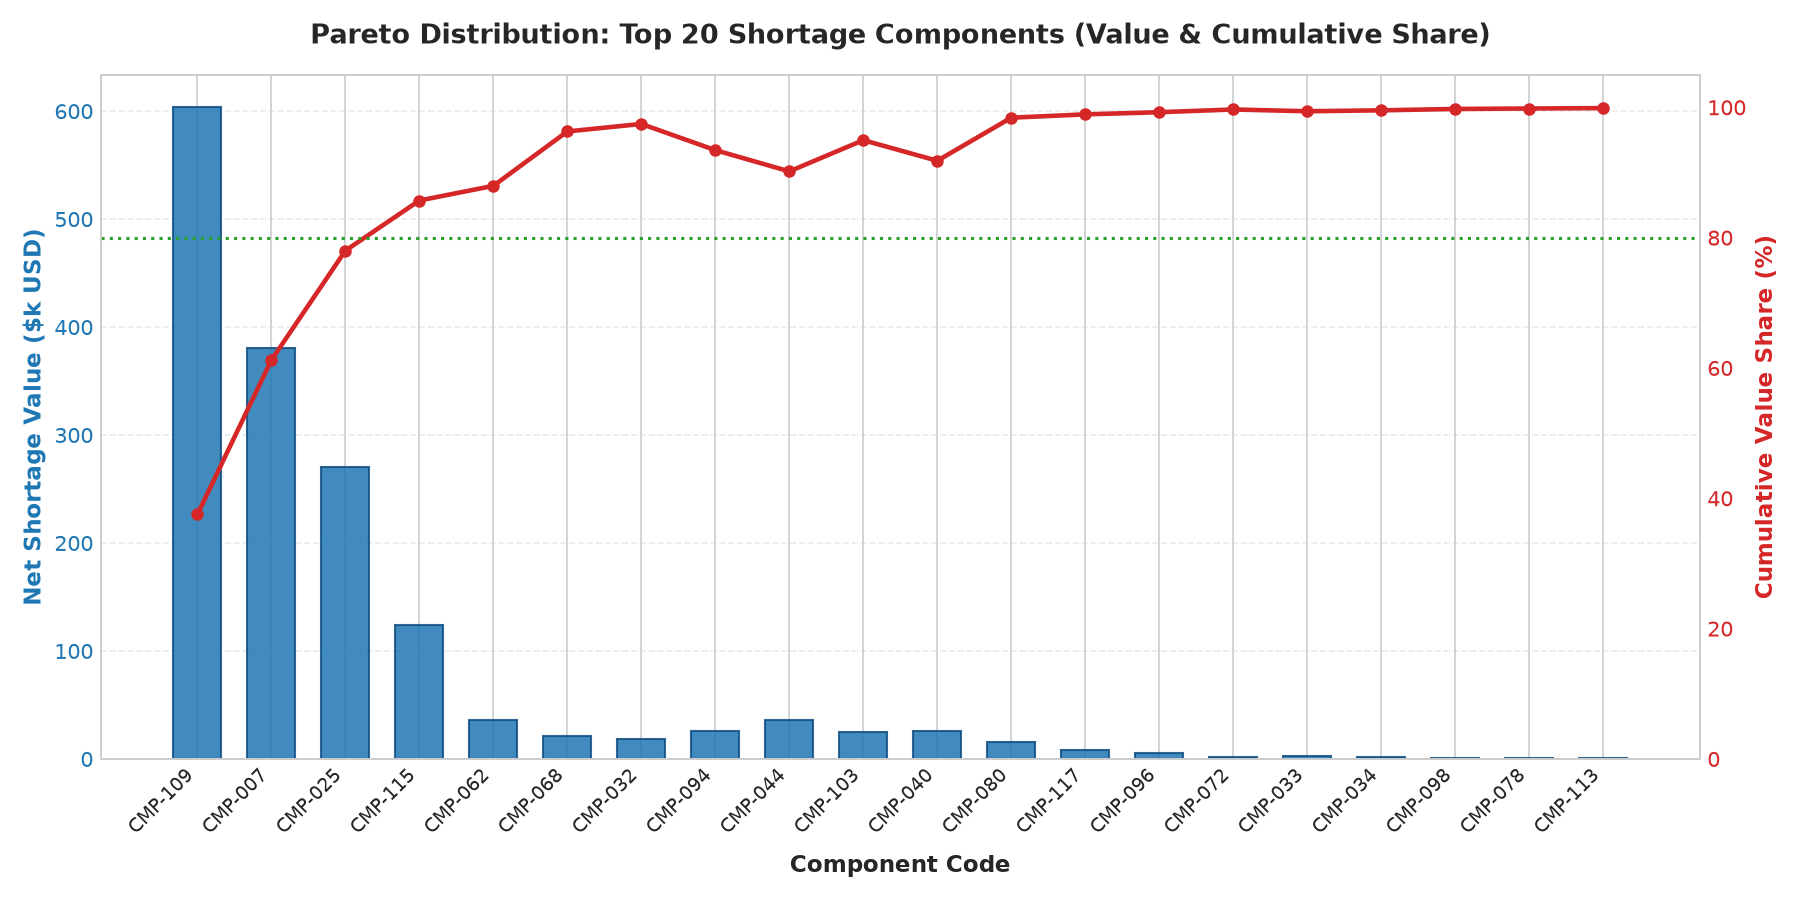


--- 02_heatmap.png ---


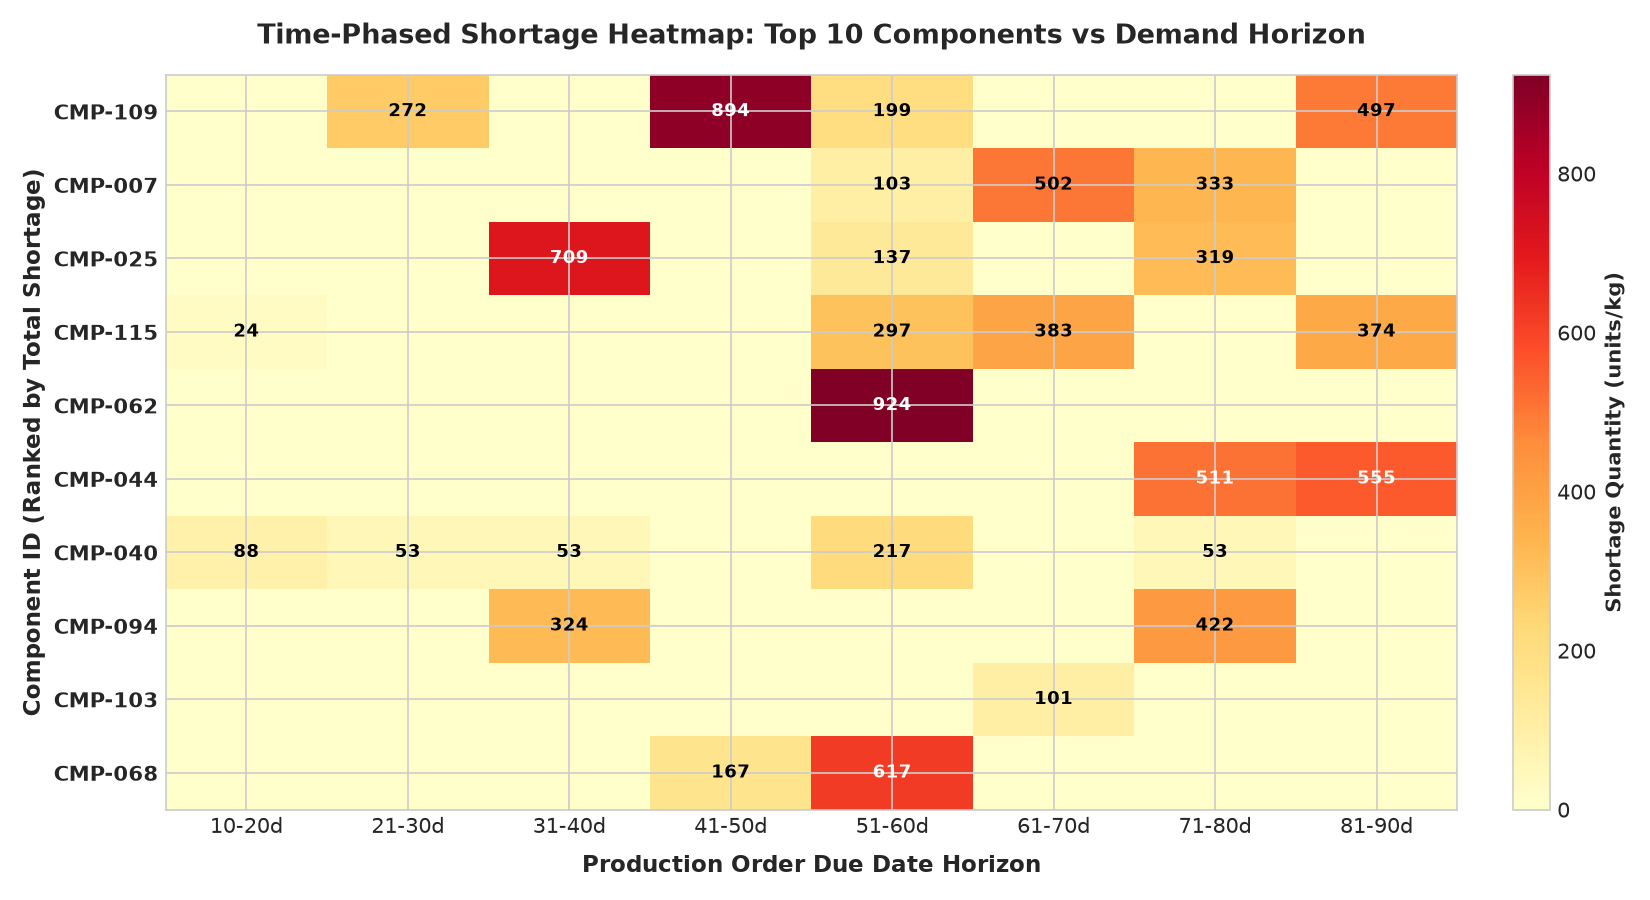


--- 03_lead_time_vs_shortage.png ---


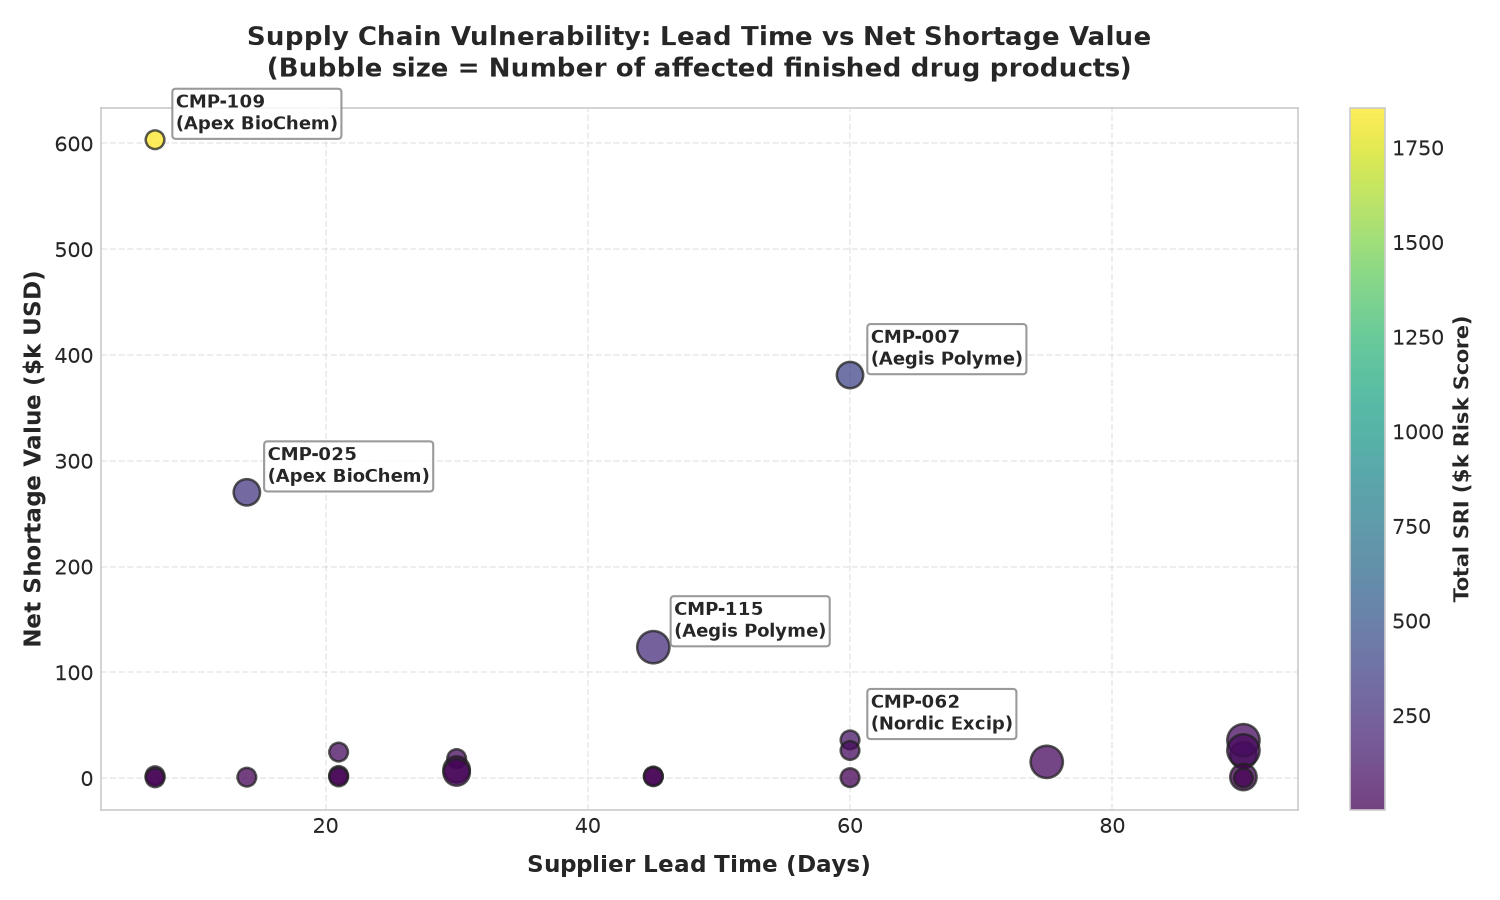


--- 04_supplier_exposure.png ---


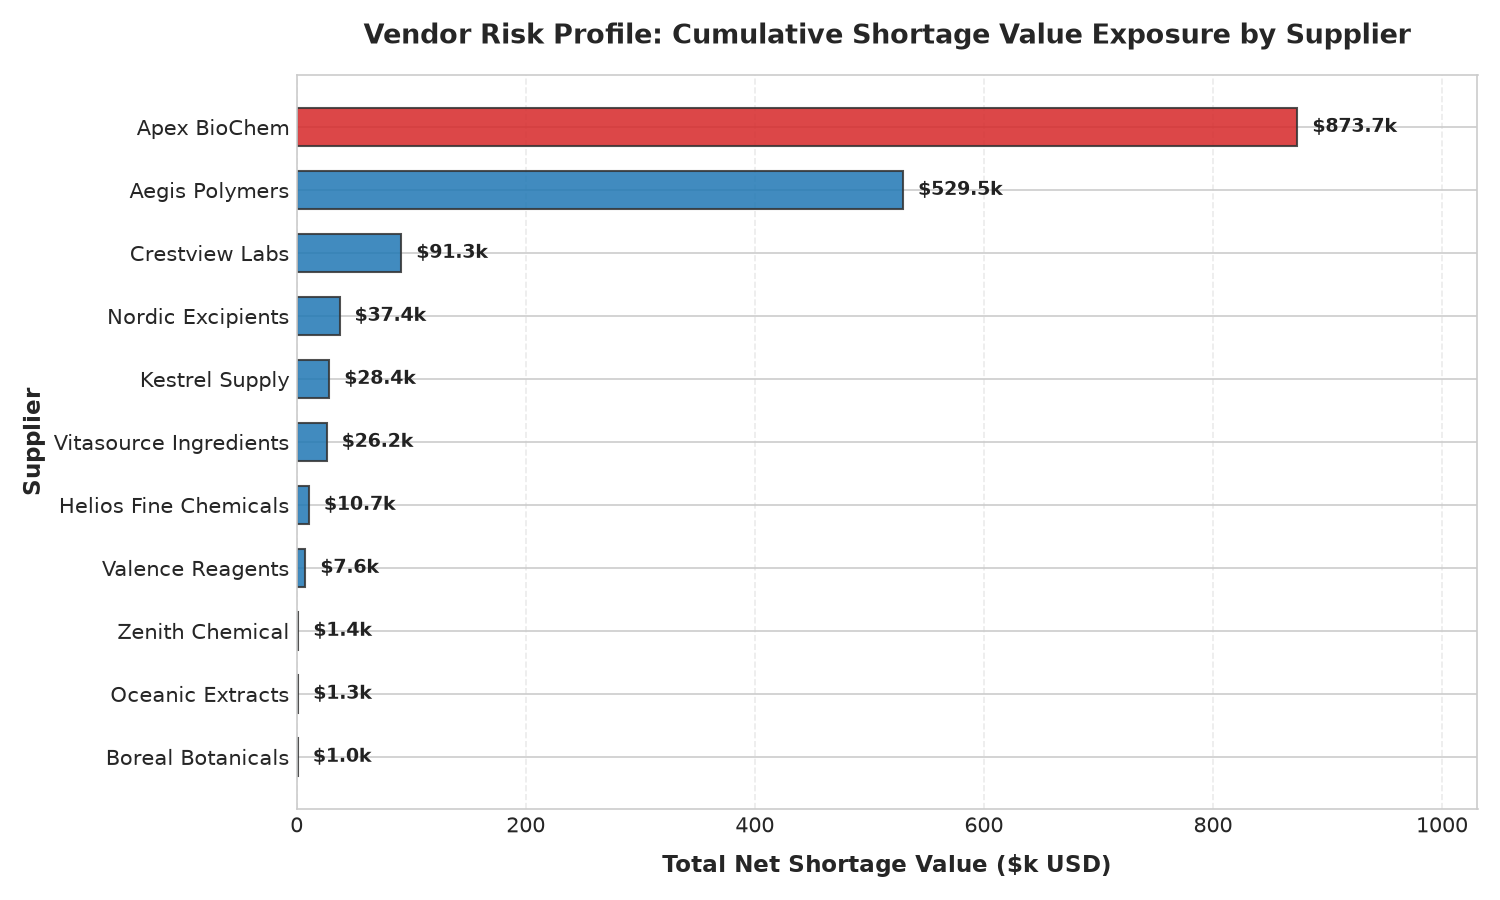

In [7]:
from IPython.display import Image, display

# Display generated charts
chart_files = [
    "charts/01_pareto.png",
    "charts/02_heatmap.png",
    "charts/03_lead_time_vs_shortage.png",
    "charts/04_supplier_exposure.png"
]

for cf in chart_files:
    if os.path.exists(cf):
        print(f"\n--- {os.path.basename(cf)} ---")
        display(Image(filename=cf))

## 7. Business Recommendations & Analytical Limitations

### Concrete Business Recommendations
1. **Apex BioChem Immediate Vendor Intervention:**
   * **Exposure:** Apex BioChem accounts for **$873,713.30 (54.32%)** of total shortage exposure, concentrated in two high-value APIs (`CMP-109` and `CMP-025`).
   * **Action:** Procurement leadership must establish a vendor-managed inventory (VMI) consignment agreement or split-sourcing protocol to compress lead time from 45 days.
2. **Prioritize SRI Top 5 Demand Lines for Expedited Air Freight:**
   * Expedite `CMP-109` and `CMP-007` shipments immediately; this unlocks **$1.85M** in Class A production orders due within 20 days.
3. **WMS Inventory Master Hygiene Protocol:**
   * Immediate cycle counting for the 5 negative-balance lots and physical isolation of the 8 expired lots currently tagged `RELEASED`.

---

### Analytical Limitations & Future Enhancements
1. **Deterministic Lead Times:** Model assumes supplier lead times are deterministic constants; stochastic lead-time distributions (Monte Carlo simulation) should be incorporated for probabilistic safety stock sizing.
2. **All-or-Nothing Batch Release:** Assumes a production order cannot start until 100% of component requirements are staged. Partial batch releases or staged dosing could unlock partial manufacturing capacity.
3. **Static Capacity Constraints:** Assumes infinite factory line capacity; coupling MRP with finite capacity scheduling (FCS) represents the logical next phase.